# Projet ENMO : asymétrie entre le bras droit et le bras gauche

**Question :** la main dominante (droitier ou gaucher) crée-t-elle une différence d'accélération entre les deux bras selon l'activité ?

**Hypothèses :**
- **H1** : à l'écriture, le bras dominant bouge plus → indice positif chez le droitier, négatif chez le gaucher.
- **H2** : à la marche, les deux bras bougent à peu près autant → indice proche de 0.
- **H3** : au clavier, les deux mains travaillent → indice proche de 0.

**Protocole :** 2 participants (Daniel = gaucher, Said = droitier). Un capteur à chaque poignet (AX6 à gauche, AX3 à droite, 100 mesures par seconde). 4 tâches de 2 minutes : repos, écriture, clavier, marche.

**Étapes :** 1. charger → 2. vérifier la qualité → 3. corriger la calibration → 4. calculer l'ENMO → 5. calculer l'indice → 6. graphiques → 7. vérifier la solidité du résultat → 8. interprétation → 9. application santé → 10. conseil santé

Après chaque étape une cellule **vérification** contrôle que le calcul est correct.

Les figures (PNG et PDF) et le tableau des résultats sont enregistrés dans le dossier `results/`.

In [1]:
# Bibliothèques utilisées
import os                          # pour créer le dossier des résultats
import numpy as np                 # calculs numériques
import pandas as pd                # tableaux de données
import matplotlib.pyplot as plt    # graphiques
import matplotlib.dates as mdates  # affichage des heures sur les graphiques

os.makedirs("results", exist_ok=True)   # crée le dossier s'il n'existe pas

def enregistrer(fig, nom):
    # Enregistre une figure dans results/, en PNG (pour le README) et en PDF (pour le rapport)
    fig.savefig(f"results/{nom}.png", dpi=150)
    fig.savefig(f"results/{nom}.pdf")

## Informations du protocole
Heures de début et de fin de chaque tâche, notées pendant les mesures.

In [2]:
taches = ["repos", "ecriture", "clavier", "marche"]
noms_taches = ["Repos", "Écriture", "Clavier", "Marche"]   # pour les graphiques

horaires = {
    "Daniel": {"repos": ("14:36", "14:38"), "ecriture": ("14:39", "14:41"),
               "clavier": ("14:43", "14:45"), "marche": ("14:47", "14:49")},
    "Said":   {"repos": ("15:07", "15:09"), "ecriture": ("15:10", "15:12"),
               "clavier": ("15:13", "15:15"), "marche": ("15:16", "15:18")},
}

lateralite = {"Daniel": "gaucher", "Said": "droitier"}

# Les mêmes couleurs dans tous les graphiques
couleur_cote = {"gauche": "tab:orange", "droite": "tab:blue"}
couleur_participant = {"Daniel": "tab:purple", "Said": "tab:green"}

## Outil de vérification
Une petite fonction qui affiche **OK** si une condition est vraie et **ERREUR** sinon. Les erreurs sont gardées dans une liste pour faire le bilan à la fin.

In [3]:
erreurs = []

def verifier(condition, message):
    if condition:
        print("OK     :", message)
    else:
        print("ERREUR :", message)
        erreurs.append(message)

## 1. Charger les données
Chaque fichier contient 4 colonnes : le temps puis l'accélération sur les axes x, y et z (en g).

On calcule la **norme** du vecteur accélération : norme = √(x² + y² + z²).

In [4]:
def norme(x, y, z):
    return (x**2 + y**2 + z**2) ** 0.5

# Vérification de la formule sur des valeurs connues
verifier(norme(3, 4, 0) == 5, "norme(3, 4, 0) = 5 (triangle 3-4-5)")
verifier(norme(0, 0, 1) == 1, "capteur immobile à plat : norme = 1 g")
verifier(norme(0, 0, -1) == 1, "le signe ne compte pas : norme(0, 0, -1) = 1 g")

OK     : norme(3, 4, 0) = 5 (triangle 3-4-5)
OK     : capteur immobile à plat : norme = 1 g
OK     : le signe ne compte pas : norme(0, 0, -1) = 1 g


In [5]:
def charger(fichier):
    df = pd.read_csv(fichier, header=None, names=["temps", "x", "y", "z"])
    df["temps"] = pd.to_datetime(df["temps"])
    df["heure"] = df["temps"].dt.strftime("%H:%M")    # ex : "14:36"
    df["norme"] = norme(df["x"], df["y"], df["z"])
    return df

# Les 4 fichiers : un par participant et par poignet
donnees = {}
for participant in ["Daniel", "Said"]:
    for cote in ["gauche", "droite"]:
        donnees[(participant, cote)] = charger(f"data/{cote}_{participant}.csv")

donnees[("Said", "droite")].head()

,temps,x,y,z,heure,norme
0,2026-11-07 15:03:42.479,0.046875,-0.921875,-0.562500,15:03,1.080952
1,2026-11-07 15:03:42.490,0.031250,-0.859375,-0.625000,15:03,1.063074
2,2026-11-07 15:03:42.500,-0.031250,-0.828125,-0.656250,15:03,1.057086
3,2026-11-07 15:03:42.509,-0.046875,-0.781250,-0.625000,15:03,1.001586
4,2026-11-07 15:03:42.520,-0.031250,-0.828125,-0.546875,15:03,0.992895


In [6]:
# Vérification du chargement
verifier(len(donnees) == 4, "4 fichiers chargés")
for (participant, cote), df in donnees.items():
    verifier(list(df.columns) == ["temps", "x", "y", "z", "heure", "norme"],
             f"{participant} {cote} : bonnes colonnes")

OK     : 4 fichiers chargés
OK     : Daniel gauche : bonnes colonnes
OK     : Daniel droite : bonnes colonnes
OK     : Said gauche : bonnes colonnes
OK     : Said droite : bonnes colonnes


## 2. Vérifier la qualité des données
- **Fréquence** : nombre de mesures par seconde (on attend environ 100).
- **Trous** : écarts de plus de 20 ms entre deux mesures (données perdues).
- **Valeurs manquantes** : cases vides dans le fichier.
- **Précision** : plus petit écart entre deux valeurs possibles du capteur.

In [7]:
for (participant, cote), df in donnees.items():
    ecarts = df["temps"].diff().dt.total_seconds()       # temps entre deux mesures (s)
    frequence = 1 / ecarts.median()
    trous = (ecarts > 0.02).sum()
    manquantes = df.isna().sum().sum()
    valeurs_x = np.sort(df["x"].unique())
    precision = np.diff(valeurs_x).min() * 1000          # en mg

    print(f"{participant} {cote} : {len(df)} mesures, {frequence:.0f} Hz, {trous} trous, "
          f"{manquantes} valeurs manquantes, précision {precision:.2f} mg")
    verifier(98 < frequence < 102, "fréquence d'environ 100 Hz")
    verifier(trous == 0, "aucun trou")
    verifier(manquantes == 0, "aucune valeur manquante")
    print()

Daniel gauche : 107040 mesures, 100 Hz, 0 trous, 0 valeurs manquantes, précision 0.24 mg
OK     : fréquence d'environ 100 Hz
OK     : aucun trou
OK     : aucune valeur manquante

Daniel droite : 108720 mesures, 100 Hz, 0 trous, 0 valeurs manquantes, précision 15.62 mg
OK     : fréquence d'environ 100 Hz
OK     : aucun trou
OK     : aucune valeur manquante

Said gauche : 88400 mesures, 100 Hz, 0 trous, 0 valeurs manquantes, précision 0.24 mg
OK     : fréquence d'environ 100 Hz
OK     : aucun trou
OK     : aucune valeur manquante

Said droite : 89760 mesures, 100 Hz, 0 trous, 0 valeurs manquantes, précision 15.62 mg
OK     : fréquence d'environ 100 Hz
OK     : aucun trou
OK     : aucune valeur manquante



**Précision :** l'AX3 (droite) n'enregistre que par paliers de **15,6 mg**, l'AX6 (gauche) par paliers de **0,24 mg**. Selon Axivity, l'AX3 en mode « packed » (10 bits) à ±8 g a une précision de 16 g / 1024 = 15,6 mg ; en mode 13 bits, elle serait de 1,9 mg. À retenir pour les très petits mouvements.

On vérifie aussi que chaque tâche contient bien 2 minutes de données (environ 12 000 mesures) et que le capteur n'a pas saturé (limite de ±8 g) pendant les tâches.

In [8]:
def pendant(df, participant, tache):
    # True pour les lignes qui sont dans la tâche, False sinon
    debut, fin = horaires[participant][tache]
    return (df["heure"] >= debut) & (df["heure"] < fin)

for (participant, cote), df in donnees.items():
    for tache in taches:
        morceau = df[pendant(df, participant, tache)]
        maximum = morceau[["x", "y", "z"]].abs().max().max()
        verifier(len(morceau) > 11500,
                 f"{participant} {cote} {tache} : {len(morceau)} mesures (2 min)")
        verifier(maximum < 7.99, f"{participant} {cote} {tache} : pas de saturation ({maximum:.2f} g max)")

OK     : Daniel gauche repos : 11844 mesures (2 min)
OK     : Daniel gauche repos : pas de saturation (1.07 g max)
OK     : Daniel gauche ecriture : 11843 mesures (2 min)
OK     : Daniel gauche ecriture : pas de saturation (1.32 g max)
OK     : Daniel gauche clavier : 11842 mesures (2 min)
OK     : Daniel gauche clavier : pas de saturation (1.64 g max)
OK     : Daniel gauche marche : 11838 mesures (2 min)
OK     : Daniel gauche marche : pas de saturation (1.64 g max)
OK     : Daniel droite repos : 12084 mesures (2 min)
OK     : Daniel droite repos : pas de saturation (1.00 g max)
OK     : Daniel droite ecriture : 12087 mesures (2 min)
OK     : Daniel droite ecriture : pas de saturation (1.12 g max)
OK     : Daniel droite clavier : 12088 mesures (2 min)
OK     : Daniel droite clavier : pas de saturation (1.80 g max)
OK     : Daniel droite marche : 12095 mesures (2 min)
OK     : Daniel droite marche : pas de saturation (1.59 g max)
OK     : Said gauche repos : 11843 mesures (2 min)
OK   

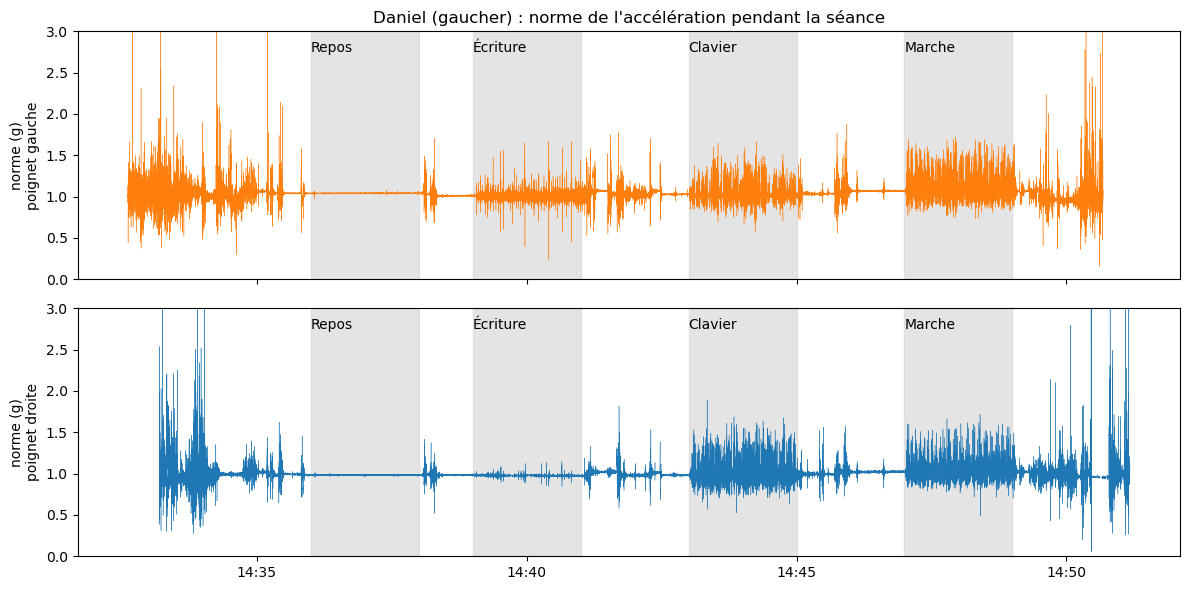

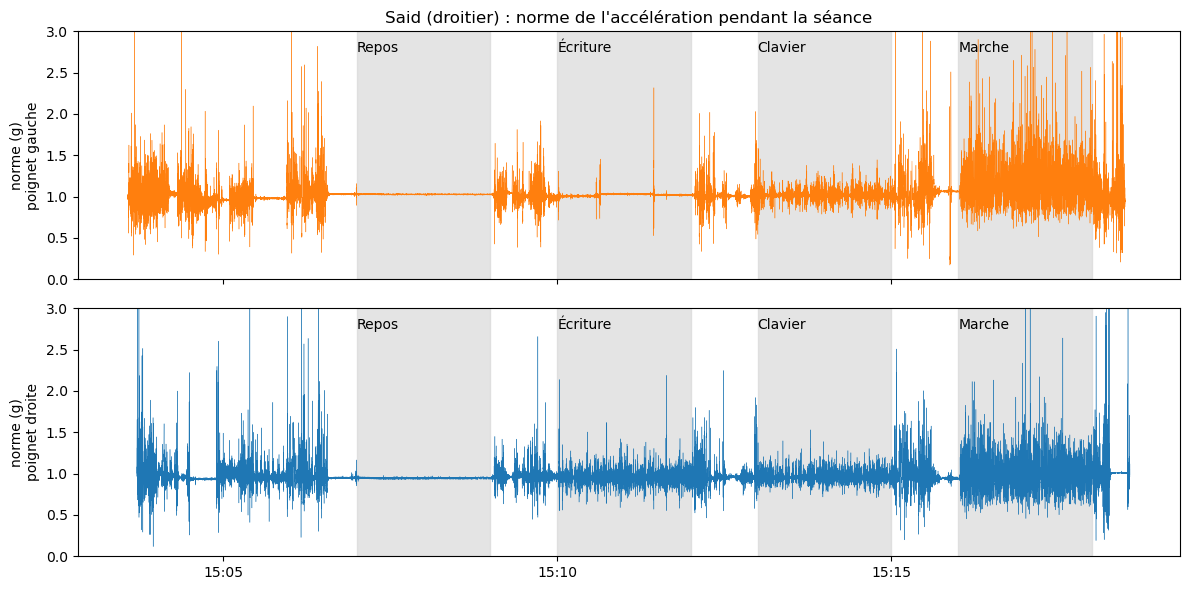

In [9]:
# Signal de chaque participant avec les 4 tâches en gris
# But : vérifier à l'oeil que le signal est propre et que les tâches se voient aux heures notées
for participant in ["Daniel", "Said"]:
    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
    for ax, cote in zip(axes, ["gauche", "droite"]):
        df = donnees[(participant, cote)]
        ax.plot(df["temps"], df["norme"], linewidth=0.3, color=couleur_cote[cote])

        # Une zone grise et le nom de la tâche pour chaque tâche
        for tache, nom in zip(taches, noms_taches):
            morceau = df[pendant(df, participant, tache)]
            ax.axvspan(morceau["temps"].iloc[0], morceau["temps"].iloc[-1],
                       color="lightgray", alpha=0.6, zorder=0)
            ax.text(morceau["temps"].iloc[0], 2.75, nom)

        ax.set_ylim(0, 3)                                 # on zoome entre 0 et 3 g
        ax.set_ylabel(f"norme (g)\npoignet {cote}")
    axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    axes[0].set_title(f"{participant} ({lateralite[participant]}) : norme de l'accélération pendant la séance")
    fig.tight_layout()
    enregistrer(fig, f"signal_{participant}")
    plt.show()

**Ce qu'on observe :**
- Les tâches se reconnaissent bien aux heures notées : repos presque plat, écriture avec de petites variations, clavier et marche plus agités.
- **Écriture :** chez Daniel (gaucher) c'est le poignet **gauche** qui bouge et le droit reste presque plat. Chez Said (droitier) c'est l'inverse. On voit déjà la dominance manuelle avant tout calcul.
- **Repos :** la ligne n'est pas exactement à 1 g (un peu au-dessus à gauche et un peu en dessous à droite). C'est le problème de calibration corrigé dans la section 3.
- Entre les tâches le signal bouge (déplacements, installation) : c'est pour ça qu'on ne garde que les zones grises.

## 3. Corriger la calibration
Au repos le capteur ne mesure que la gravité : la norme devrait valoir **exactement 1 g**.
Ce n'est pas le cas, le capteur gauche (AX6) mesure un peu plus de 1 g et le droit (AX3) un peu moins.

Sans correction le bras gauche paraîtrait toujours plus actif même au repos : ce serait une **fausse asymétrie**. L'ENMO est connu pour être sensible à une mauvaise calibration (Bakrania et al., 2016).

**Correction :** on divise la norme par sa valeur moyenne au repos. Après correction, le repos vaut 1 g.

In [10]:
facteurs = {}
for (participant, cote), df in donnees.items():
    repos = pendant(df, participant, "repos")
    norme_repos = df.loc[repos, "norme"].mean()      # devrait valoir 1 g
    facteurs[(participant, cote)] = norme_repos
    df["norme_corrigee"] = df["norme"] / norme_repos
    print(f"{participant} {cote} : norme au repos = {norme_repos:.3f} g "
          f"(erreur de {abs(norme_repos - 1) * 1000:.0f} mg)")

Daniel gauche : norme au repos = 1.040 g (erreur de 40 mg)
Daniel droite : norme au repos = 0.981 g (erreur de 19 mg)
Said gauche : norme au repos = 1.027 g (erreur de 27 mg)
Said droite : norme au repos = 0.949 g (erreur de 51 mg)


In [11]:
# Vérification de la correction
for (participant, cote), df in donnees.items():
    repos = pendant(df, participant, "repos")
    apres = df.loc[repos, "norme_corrigee"].mean()
    verifier(round(apres, 3) == 1.000, f"{participant} {cote} : repos = {apres:.3f} g après correction")
    verifier(0.9 < facteurs[(participant, cote)] < 1.1, f"{participant} {cote} : erreur du capteur plausible (< 10 %)")

OK     : Daniel gauche : repos = 1.000 g après correction
OK     : Daniel gauche : erreur du capteur plausible (< 10 %)
OK     : Daniel droite : repos = 1.000 g après correction
OK     : Daniel droite : erreur du capteur plausible (< 10 %)
OK     : Said gauche : repos = 1.000 g après correction
OK     : Said gauche : erreur du capteur plausible (< 10 %)
OK     : Said droite : repos = 1.000 g après correction
OK     : Said droite : erreur du capteur plausible (< 10 %)


Le repos vaut 1,000 g pour les 4 capteurs. Ce n'est pas une preuve que la correction est parfaite : le facteur est calculé **à partir du repos**, donc le repos vaut forcément 1 g après. Cela vérifie seulement que le calcul a bien été fait.

Les erreurs trouvées (19 à 51 mg) sont du même ordre que dans la littérature : avant correction, van Hees et al. (2014) rapportent des erreurs allant de 16,6 mg (cohorte du Koweït) à 76,7 mg (cohorte du Brésil).

**Limite :** le facteur est calculé dans une seule position (bras posé sur la table). La méthode complète d'autocalibration (van Hees et al., 2014) utilise de longs enregistrements où le poignet reste immobile dans beaucoup de positions différentes : elle n'est pas applicable à nos 15 à 18 minutes.

## 4. Calculer l'ENMO
**ENMO = norme − 1 g**, et on remplace les valeurs négatives par 0.

On enlève 1 g pour retirer la gravité, il ne reste que l'accélération due au mouvement. Le résultat est exprimé en **mg** (milli-g, 1 g = 1000 mg).

In [12]:
def enmo(norme):
    return (norme - 1).clip(lower=0) * 1000

# Vérification de la formule sur des valeurs connues
test = enmo(pd.Series([1.0, 1.5, 0.8]))
verifier(test[0] == 0, "norme 1 g (immobile) -> ENMO = 0 mg")
verifier(test[1] == 500, "norme 1,5 g -> ENMO = 500 mg")
verifier(test[2] == 0, "norme 0,8 g (< 1 g) -> ENMO = 0 mg (valeur négative remplacée par 0)")

OK     : norme 1 g (immobile) -> ENMO = 0 mg
OK     : norme 1,5 g -> ENMO = 500 mg
OK     : norme 0,8 g (< 1 g) -> ENMO = 0 mg (valeur négative remplacée par 0)


On calcule deux ENMO : **avant correction** (avec la norme brute) et **après correction** (avec la norme corrigée). Dans le tableau de la section 5, les colonnes « avant » montrent les mg « fantômes » dus à la calibration, par exemple au repos sur le poignet gauche.

In [13]:
for (participant, cote), df in donnees.items():
    df["enmo_brut"] = enmo(df["norme"])            # sans correction
    df["enmo"] = enmo(df["norme_corrigee"])        # avec correction
    verifier(df["enmo"].min() >= 0, f"{participant} {cote} : ENMO jamais négatif")

OK     : Daniel gauche : ENMO jamais négatif
OK     : Daniel droite : ENMO jamais négatif
OK     : Said gauche : ENMO jamais négatif
OK     : Said droite : ENMO jamais négatif


## 5. Calculer l'indice d'asymétrie
Pour chaque personne et chaque tâche on compare **ses deux poignets** :

**Indice = (ENMO droit − ENMO gauche) / (ENMO droit + ENMO gauche)**

- **0** : les deux bras bougent autant
- **proche de +1** : le bras droit bouge plus
- **proche de −1** : le bras gauche bouge plus

Cette formule a la même forme que le *Symmetry Index* de Robinson et al. (1987) utilisé pour mesurer l'asymétrie de la marche (Alves et al., 2020).

In [14]:
def indice(D, G):
    return (D - G) / (D + G)

# Vérification avec les exemples du sujet
verifier(round(indice(2, 1), 2) == 0.33, "droite = 2, gauche = 1 -> +0,33")
verifier(round(indice(1, 2), 2) == -0.33, "droite = 1, gauche = 2 -> -0,33 (symétrique)")
verifier(indice(1, 1) == 0, "deux bras pareils -> 0")
verifier(indice(5, 0) == 1, "seul le bras droit bouge -> +1")
verifier(indice(0, 5) == -1, "seul le bras gauche bouge -> -1")

OK     : droite = 2, gauche = 1 -> +0,33
OK     : droite = 1, gauche = 2 -> -0,33 (symétrique)
OK     : deux bras pareils -> 0
OK     : seul le bras droit bouge -> +1
OK     : seul le bras gauche bouge -> -1


In [15]:
def enmo_moyen(participant, cote, tache, colonne="enmo"):
    df = donnees[(participant, cote)]
    return df.loc[pendant(df, participant, tache), colonne].mean()

lignes = []
for participant in ["Daniel", "Said"]:
    for tache in taches:
        # Avec correction
        D = enmo_moyen(participant, "droite", tache)
        G = enmo_moyen(participant, "gauche", tache)
        # Sans correction
        D_brut = enmo_moyen(participant, "droite", tache, "enmo_brut")
        G_brut = enmo_moyen(participant, "gauche", tache, "enmo_brut")
        lignes.append({
            "participant": participant,
            "tache": tache,
            "ENMO gauche avant (mg)": G_brut,
            "ENMO gauche (mg)": G,
            "ENMO droit avant (mg)": D_brut,
            "ENMO droit (mg)": D,
            "D + G (mg)": D + G,
            "indice": indice(D, G),
            "indice sans correction": indice(D_brut, G_brut),
        })

resultats = pd.DataFrame(lignes)
resultats.round(3).to_csv("results/resultats.csv", index=False)   # tableau enregistré
resultats.round(2)      # on arrondit seulement pour l'affichage

,participant,tache,ENMO gauche avant (mg),ENMO gauche (mg),ENMO droit avant (mg),ENMO droit (mg),D + G (mg),indice,indice sans correction
0,Daniel,repos,39.79,1.11,0.00,3.25,4.36,0.49,-1.00
1,Daniel,ecriture,20.70,6.76,0.46,1.98,8.74,-0.55,-0.96
2,Daniel,clavier,36.04,17.58,34.40,42.04,59.63,0.41,-0.02
3,Daniel,marche,114.83,85.38,68.36,80.94,166.32,-0.03,-0.25
4,Said,repos,27.27,1.22,0.00,1.86,3.08,0.21,-1.00
5,Said,ecriture,22.30,3.37,12.30,31.62,34.99,0.81,-0.29
6,Said,clavier,29.95,13.40,6.94,23.54,36.93,0.27,-0.62
7,Said,marche,177.71,155.52,78.19,108.37,263.89,-0.18,-0.39


In [16]:
# Vérification des indices
for i in range(len(resultats)):
    ligne = resultats.iloc[i]
    verifier(-1 <= ligne["indice"] <= 1, f"{ligne['participant']} {ligne['tache']} : indice entre -1 et 1")

# Détail du calcul: Said, écriture
ligne = resultats[(resultats["participant"] == "Said") & (resultats["tache"] == "ecriture")].iloc[0]
D, G = ligne["ENMO droit (mg)"], ligne["ENMO gauche (mg)"]
print(f"Said écriture : D = {D:.1f} mg, G = {G:.1f} mg -> ({D:.1f} - {G:.1f}) / ({D:.1f} + {G:.1f}) = {(D - G) / (D + G):.2f}")
verifier(abs(ligne["indice"] - (D - G) / (D + G)) < 1e-9, "même résultat que le calcul à la main")

OK     : Daniel repos : indice entre -1 et 1
OK     : Daniel ecriture : indice entre -1 et 1
OK     : Daniel clavier : indice entre -1 et 1
OK     : Daniel marche : indice entre -1 et 1
OK     : Said repos : indice entre -1 et 1
OK     : Said ecriture : indice entre -1 et 1
OK     : Said clavier : indice entre -1 et 1
OK     : Said marche : indice entre -1 et 1
Said écriture : D = 31.6 mg, G = 3.4 mg -> (31.6 - 3.4) / (31.6 + 3.4) = 0.81
OK     : même résultat que le calcul à la main


**Attention au repos :** D + G ne vaut que 3 à 4 mg, moins que la précision de l'AX3 (15,6 mg). Quand les deux valeurs sont très petites par rapport à l'erreur de mesure l'indice est gonflé artificiellement (Alves et al., 2020) : **il n'est pas interprétable au repos.**

## 6. Graphiques

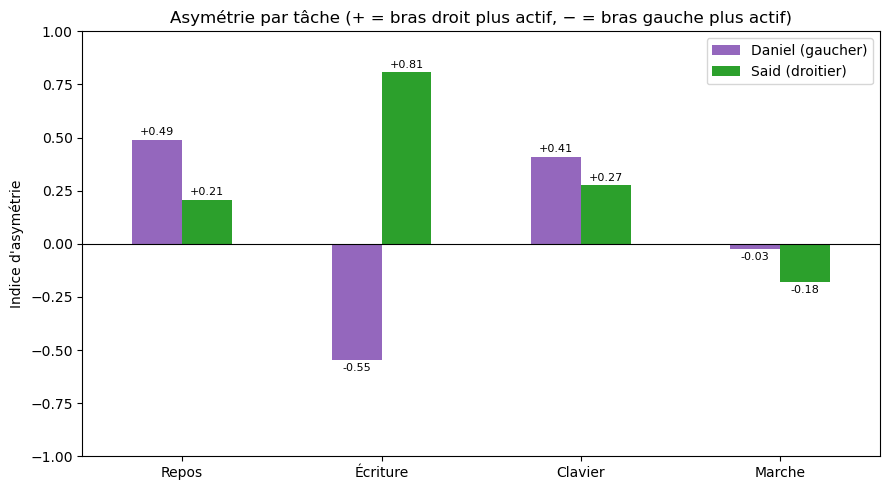

In [17]:
# Indice d'asymétrie par tâche : Daniel (gaucher) et Said (droitier) côte à côte
tableau = resultats.pivot(index="tache", columns="participant", values="indice")
tableau = tableau.loc[taches]                       # remet les tâches dans l'ordre
tableau = tableau.rename(columns={"Daniel": "Daniel (gaucher)", "Said": "Said (droitier)"})

fig, ax = plt.subplots(figsize=(9, 5))
tableau.plot.bar(ax=ax, rot=0, color=[couleur_participant["Daniel"], couleur_participant["Said"]])
ax.axhline(0, color="black", linewidth=0.8)
for barres in ax.containers:                         # écrit la valeur au-dessus de chaque barre
    ax.bar_label(barres, fmt="%+.2f", padding=2, fontsize=8)
ax.set_xticklabels(noms_taches)
ax.set_xlabel("")
ax.set_ylim(-1, 1)
ax.legend(title="")                                  # enlève le titre « participant » de la légende
ax.set_ylabel("Indice d'asymétrie")
ax.set_title("Asymétrie par tâche (+ = bras droit plus actif, − = bras gauche plus actif)")
fig.tight_layout()
enregistrer(fig, "indice_asymetrie")
plt.show()

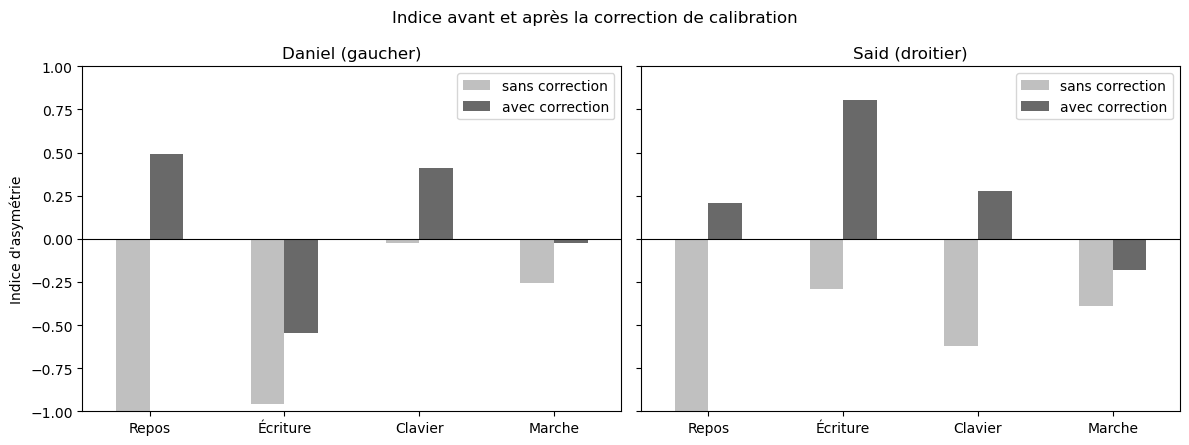

In [18]:
# Effet de la correction : indice sans et avec correction pour chaque participant
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, participant in zip(axes, ["Daniel", "Said"]):
    t = resultats[resultats["participant"] == participant].set_index("tache")
    t = t[["indice sans correction", "indice"]]
    t = t.rename(columns={"indice sans correction": "sans correction", "indice": "avec correction"})
    t.plot.bar(ax=ax, rot=0, color=["silver", "dimgray"])   # la légende prend le nom des colonnes
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticklabels(noms_taches)
    ax.set_xlabel("")
    ax.set_ylim(-1, 1)
    ax.set_title(f"{participant} ({lateralite[participant]})")
axes[0].set_ylabel("Indice d'asymétrie")
fig.suptitle("Indice avant et après la correction de calibration")
fig.tight_layout()
enregistrer(fig, "avant_apres_correction")
plt.show()

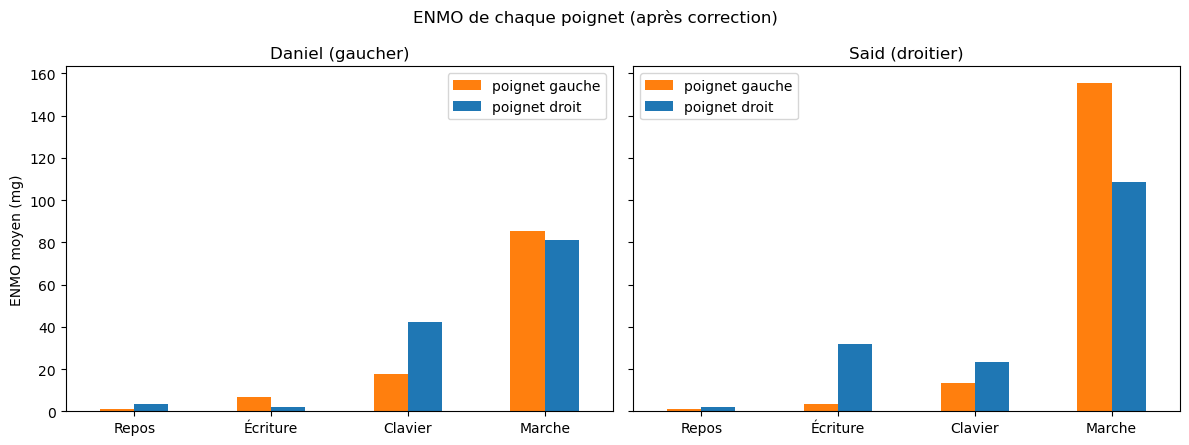

In [19]:
# ENMO de chaque poignet après correction pour chaque participant
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, participant in zip(axes, ["Daniel", "Said"]):
    t = resultats[resultats["participant"] == participant].set_index("tache")
    t = t[["ENMO gauche (mg)", "ENMO droit (mg)"]]
    t = t.rename(columns={"ENMO gauche (mg)": "poignet gauche", "ENMO droit (mg)": "poignet droit"})
    t.plot.bar(ax=ax, rot=0, color=[couleur_cote["gauche"], couleur_cote["droite"]])
    ax.set_xticklabels(noms_taches)
    ax.set_xlabel("")
    ax.set_title(f"{participant} ({lateralite[participant]})")
axes[0].set_ylabel("ENMO moyen (mg)")
fig.suptitle("ENMO de chaque poignet (après correction)")
fig.tight_layout()
enregistrer(fig, "enmo_par_poignet")
plt.show()

## 7. Vérifier la solidité du résultat
Un seul indice par tâche ne dit pas si le résultat est stable. On découpe chaque tâche en **fenêtres de 5 secondes** (24 fenêtres par tâche) et on calcule l'indice dans chacune. Si l'effet est réel la plupart des fenêtres doivent aller dans le même sens. Les fenêtres de 5 s sont celles utilisées dans les études sur l'ENMO (Bakrania et al., 2016).

In [20]:
def enmo_par_fenetre(participant, cote, tache):
    df = donnees[(participant, cote)]
    morceau = df[pendant(df, participant, tache)].set_index("temps")
    return morceau["enmo"].resample("5s").mean()      # une moyenne toutes les 5 s

lignes = []
indices_fenetres = {}
for participant in ["Daniel", "Said"]:
    for tache in taches:
        D = enmo_par_fenetre(participant, "droite", tache)
        G = enmo_par_fenetre(participant, "gauche", tache)
        indices_5s = indice(D, G).dropna()             # un indice par fenêtre
        indices_fenetres[(participant, tache)] = indices_5s
        lignes.append({
            "participant": participant,
            "tache": tache,
            "nb fenêtres": len(indices_5s),
            "moyenne": indices_5s.mean(),
            "écart-type": indices_5s.std(),
            "fenêtres > 0": (indices_5s > 0).sum(),
            "fenêtres < 0": (indices_5s < 0).sum(),
        })

fenetres = pd.DataFrame(lignes)
verifier((fenetres["nb fenêtres"] == 24).all(), "24 fenêtres de 5 s par tâche (2 min)")
fenetres.round(2)

OK     : 24 fenêtres de 5 s par tâche (2 min)


,participant,tache,nb fenêtres,moyenne,écart-type,fenêtres > 0,fenêtres < 0
0,Daniel,repos,24,0.49,0.07,24,0
1,Daniel,ecriture,24,-0.52,0.35,2,22
2,Daniel,clavier,24,0.42,0.21,24,0
3,Daniel,marche,24,-0.03,0.06,9,15
4,Said,repos,24,0.16,0.23,19,5
5,Said,ecriture,24,0.83,0.23,24,0
6,Said,clavier,24,0.30,0.22,22,2
7,Said,marche,24,-0.18,0.11,2,22


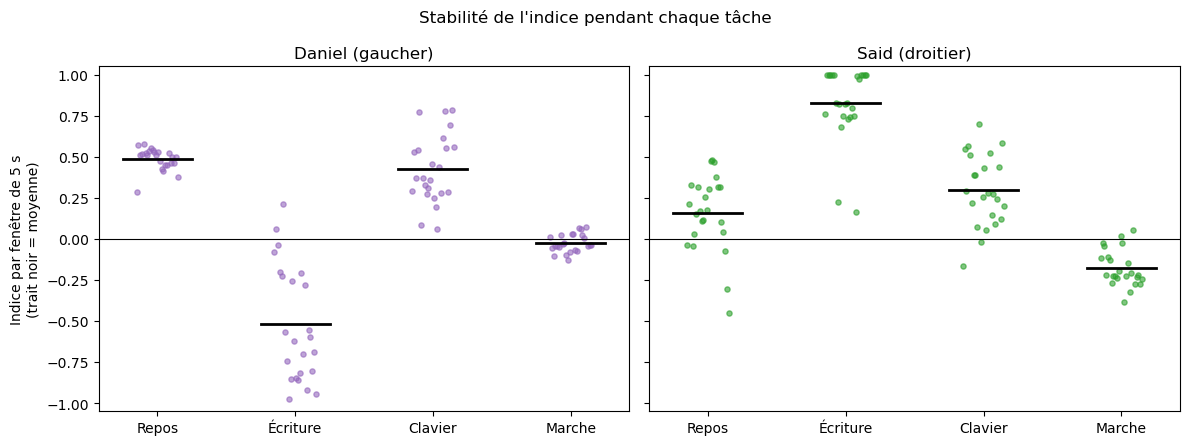

In [21]:
# Indice de chaque fenêtre de 5 s (un point = une fenêtre)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, participant in zip(axes, ["Daniel", "Said"]):
    for i, tache in enumerate(taches):
        valeurs = indices_fenetres[(participant, tache)]
        decalage = np.linspace(-0.15, 0.15, len(valeurs))    # écarte un peu les points
        ax.scatter(i + decalage, valeurs, s=14, color=couleur_participant[participant], alpha=0.6)
        ax.plot([i - 0.25, i + 0.25], [valeurs.mean()] * 2, color="black", linewidth=2)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(range(len(taches)))
    ax.set_xticklabels(noms_taches)
    ax.set_ylim(-1.05, 1.05)
    ax.set_title(f"{participant} ({lateralite[participant]})")
axes[0].set_ylabel("Indice par fenêtre de 5 s\n(trait noir = moyenne)")
fig.suptitle("Stabilité de l'indice pendant chaque tâche")
fig.tight_layout()
enregistrer(fig, "indice_fenetres_5s")
plt.show()

In [22]:
# Hypothèse H1 : indice positif chez le droitier, négatif chez le gaucher à l'écriture
ecriture = resultats[resultats["tache"] == "ecriture"].set_index("participant")["indice"]
f_daniel = fenetres[(fenetres["participant"] == "Daniel") & (fenetres["tache"] == "ecriture")].iloc[0]
f_said = fenetres[(fenetres["participant"] == "Said") & (fenetres["tache"] == "ecriture")].iloc[0]

verifier(ecriture["Said"] > 0 and ecriture["Daniel"] < 0,
         f"H1 sur toute la tâche : Said {ecriture['Said']:+.2f}, Daniel {ecriture['Daniel']:+.2f}")
verifier(f_said["fenêtres > 0"] > 12 and f_daniel["fenêtres < 0"] > 12,
         f"H1 dans la majorité des fenêtres de 5 s : Said {f_said['fenêtres > 0']}/24 positives, "
         f"Daniel {f_daniel['fenêtres < 0']}/24 négatives")

OK     : H1 sur toute la tâche : Said +0.81, Daniel -0.55
OK     : H1 dans la majorité des fenêtres de 5 s : Said 24/24 positives, Daniel 22/24 négatives


## 8. Interprétation

- **Écriture (H1 confirmée) :** l'indice est **négatif chez Daniel (gaucher)** et **positif chez Said (droitier)**. L'inversion se retrouve dans presque toutes les fenêtres de 5 s (Said 24/24, Daniel 22/24) : ce n'est pas un hasard. C'est cohérent avec Bailey et al. (2014), où l'écriture fait partie des rares tâches réalisées de façon presque unimanuelle. Le bras non dominant n'est pas à zéro : il tient la feuille.
- **Marche (H2 en partie) :** l'indice est proche de 0 mais légèrement **négatif chez les deux** (bras gauche un peu plus actif). C'est ce que décrit la littérature : chez 334 adultes, le balancement du bras gauche était en moyenne plus grand et la latéralité n'avait pas d'effet sur cette asymétrie (Killeen et al., 2018). Attention : dans cette étude 91 % des participants étaient droitiers et l'âge moyen était de 68,6 ans.
- **Clavier (H3 non tranchée) :** les deux participants penchent vers la droite **mais** les mouvements sont petits (quelques dizaines de mg) donc très sensibles à la calibration et à la précision de l'AX3 -> il faut rester prudent. À discuter (exemple : Utilisation des fleches du clavier?).
- **Repos :** l'ENMO ne vaut que quelques mg en dessous de la précision de l'AX3. L'indice n'est pas interprétable.
- **Sans correction de calibration** (colonnes « avant »), le bras gauche recevait des mg « fantômes » et toutes les tâches semblaient pencher vers la gauche. Pour Said l'indice de l'écriture change même de signe. Vérifier la qualité des données était indispensable.

**Limites :** seulement 2 participants, une seule mesure par tâche, deux modèles de capteurs différents (précision 15,6 mg pour l'AX3 contre 0,24 mg pour l'AX6), correction de calibration simplifiée (calculé dans une seule position).

## 9. Application santé
Mesurer l'utilisation de chaque bras dans la vie quotidienne sert au suivi des patients après un AVC : chez les adultes sans handicap les deux bras sont utilisés de façon équivalente au cours d'une journée alors qu'après un AVC l'activité est plus faible et plus latéralisée (Bailey et al., 2015). Un indice d'asymétrie calculé chaque semaine permettrait de suivre la récupération d'un patient.

## 10. Conseil santé
Nos mesures permettent de comparer **combien les poignets bougent** pendant le travail de bureau (écriture, clavier) et pendant la marche.

In [23]:
# Mouvement total des deux poignets (D + G) : marche comparée au travail de bureau
for participant in ["Daniel", "Said"]:
    r = resultats[resultats["participant"] == participant].set_index("tache")
    bureau = (r.loc["ecriture", "D + G (mg)"] + r.loc["clavier", "D + G (mg)"]) / 2
    marche = r.loc["marche", "D + G (mg)"]
    print(f"{participant} : travail de bureau = {bureau:.0f} mg, marche = {marche:.0f} mg "
          f"-> la marche produit {marche / bureau:.1f} fois plus de mouvement")

Daniel : travail de bureau = 34 mg, marche = 166 mg -> la marche produit 4.9 fois plus de mouvement
Said : travail de bureau = 36 mg, marche = 264 mg -> la marche produit 7.3 fois plus de mouvement


**Conseils :**

1. **Pour les personnes qui travaillent assises (étudiants, travail de bureau).** Pendant l'écriture et le clavier l'ENMO est faible : quelques dizaines de mg seulement. La marche produit plusieurs fois plus de mouvement et ce n'est qu'une marche à vitesse normale. L'OMS recommande de **limiter le temps sédentaire** et de le remplacer par une activité physique de n'importe quelle intensité ainsi que **150 à 300 minutes d'activité modérée par semaine** (Bull et al., 2020). Conseil concret : couper régulièrement le travail assis par quelques minutes de marche par exemple entre deux tâches ou pendant un appel.

2. **Pour le suivi d'un patient après un AVC.** Deux capteurs aux poignets et ce notebook forment un **outil numérique simple** : l'indice d'asymétrie dit quel bras est utilisé et de combien. Chez l'adulte sans handicap les deux bras sont utilisés de façon équivalente sur une journée (Bailey et al., 2015). Un kinésithérapeute ou un ergothérapeute pourrait mesurer l'indice chaque semaine. Un indice qui se rapproche de 0 sur une journée montrerait que le patient utilise de nouveau son bras atteint. Le conseil au patient serait d'utiliser ce bras dans les gestes du quotidien et pas seulement pendant les séances.

3. **Pour bien mesurer.** Notre projet montre que la mesure doit être préparée : utiliser **le même modèle de capteur** aux deux poignets, **vérifier la calibration** avant de mesurer (capteur posé immobile dans plusieurs positions) et enregistrer **une journée entière** plutôt que quelques minutes pour obtenir un indice représentatif.

## Références
- Alves SA, Ehrig RM, Raffalt PC, Bender A, Duda GN, Agres AN (2020). Quantifying asymmetry in gait: the weighted universal symmetry index to evaluate 3D ground reaction forces. *Front Bioeng Biotechnol* 8:579511.
- Bailey RR, Klaesner JW, Lang CE (2014). An accelerometry-based methodology for assessment of real-world bilateral upper extremity activity. *PLoS ONE* 9(7):e103135.
- Bailey RR, Klaesner JW, Lang CE (2015). Quantifying real-world upper-limb activity in nondisabled adults and adults with chronic stroke. *Neurorehabil Neural Repair* 29(10):969-978.
- Bakrania K et al. (2016). Intensity thresholds on raw acceleration data: Euclidean Norm Minus One (ENMO) and Mean Amplitude Deviation (MAD) approaches. *PLoS ONE* 11(10):e0164045.
- Bull FC, Al-Ansari SS, Biddle S et al. (2020). World Health Organization 2020 guidelines on physical activity and sedentary behaviour. *Br J Sports Med* 54(24):1451-1462.
- Killeen T, Elshehabi M, Filli L et al. (2018). Arm swing asymmetry in overground walking. *Sci Rep* 8(1):12803.
- Robinson RO, Herzog W, Nigg BM (1987). Use of force platform variables to quantify the effects of chiropractic manipulation on gait symmetry. *J Manipulative Physiol Ther* 10(4):172-176.
- van Hees VT et al. (2013). Separating movement and gravity components in an acceleration signal and implications for the assessment of human daily physical activity. *PLoS ONE* 8(4):e61691.
- van Hees VT, Fang Z, Langford J et al. (2014). Autocalibration of accelerometer data for free-living physical activity assessment using local gravity and temperature: an evaluation on four continents. *J Appl Physiol* 117(7):738-744.
- Axivity, « AX3 sensitivities and bit depths » (documentation du capteur).

In [24]:
# Bilan de toutes les vérifications
if len(erreurs) == 0:
    print("Toutes les vérifications sont OK.")
else:
    print(f"{len(erreurs)} vérification(s) en erreur :")
    for e in erreurs:
        print(" -", e)

Toutes les vérifications sont OK.
